In [2]:
import torch
import torch.nn as nn
import numpy as np
import scipy.io
from matplotlib import pyplot as plt
import matplotlib.animation as animation

## Generating Data

In [3]:
# Define the coordinates for the square's corners
x_min, y_min = 0, 0  # Lower-left corner
x_max, y_max = 1.0, 1.0  # Upper-right corner for a square with side length 1
t_min, t_max = 0, 10

In [4]:
##Generating Data
a=0.1
gamma=1
beta=0.5
eps=0.01
delta=0.0


dx=0.5
dt=0.1

diff = 0.5 ## diffusion coefficient
endtime=200 ## length of simulation in physical time units
nend=int(np.ceil(endtime/dt)) ## length of simulation in time steps
# outputevery=5  ##save u variable for display every this many time units
# nout=np.ceil(endtime/outputevery) ##number of times to output
# kout=1 ##index for output
nx = 100 ##2d square length in gridpoints; physical length is nx * dx


u=np.zeros((nx,nx), dtype= float); ##fast "voltage"-like variable
v=np.zeros((nx,nx), dtype=float); ##slow recovery variable
print(u.shape, v.shape, np.arange(np.ceil(nx/2), dtype = int).shape)


# u[0:25, 0:25] = 0.5



(100, 100) (100, 100) (50,)


In [5]:
radius = nx // 4

for i in range(nx):
    for j in range(nx):
        if i**2 + j**2 <= radius**2:
            u[i, j] = 0.5

In [6]:
radius = nx // 4

x = np.arange(nx)
y = np.arange(nx)
X, Y = np.meshgrid(x, y, indexing='ij')

mask = X**2 + Y**2 <= radius**2
u[mask] = 0.5

In [7]:
v1=v.copy()
u1 =u.copy()
training_points = np.zeros((100,100,100))
training_points_v = np.zeros((100,100,100))

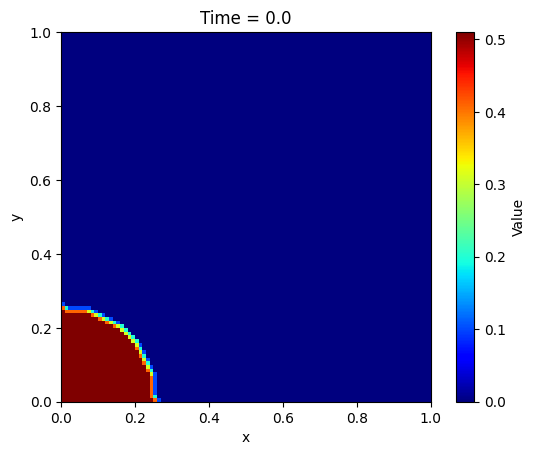

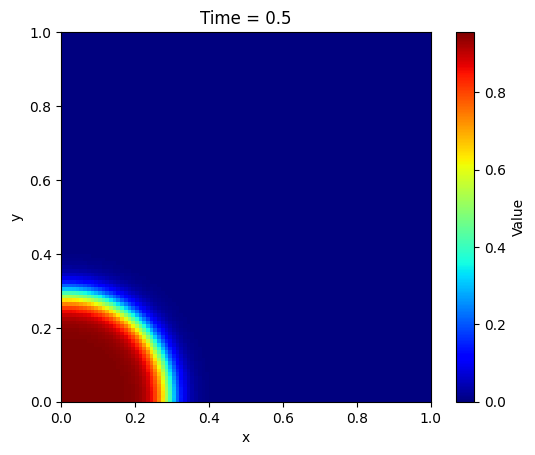

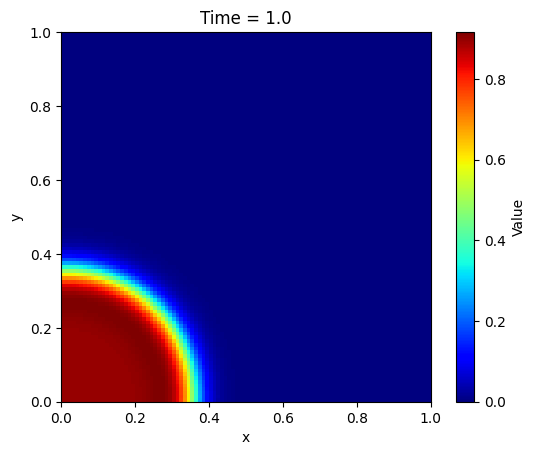

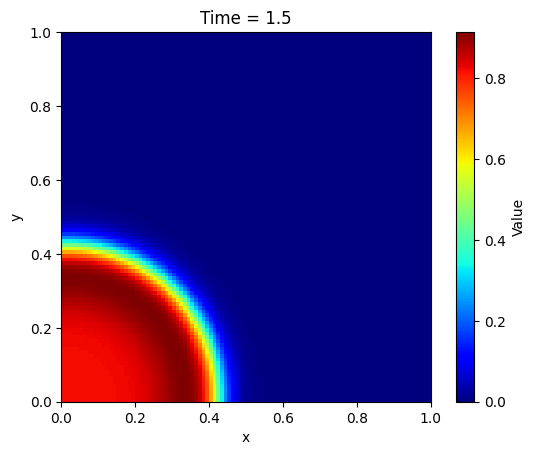

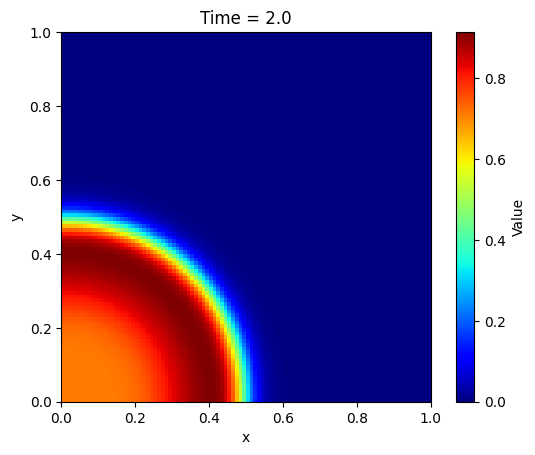

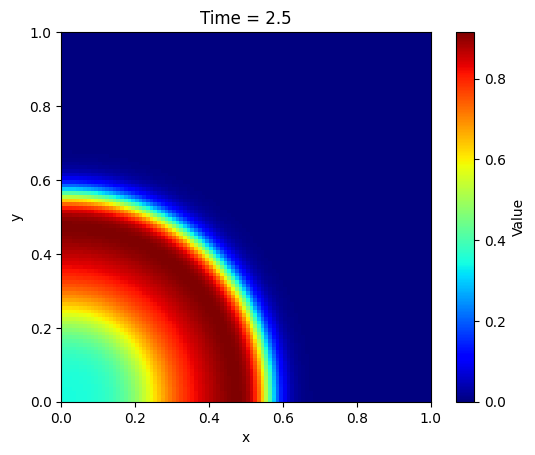

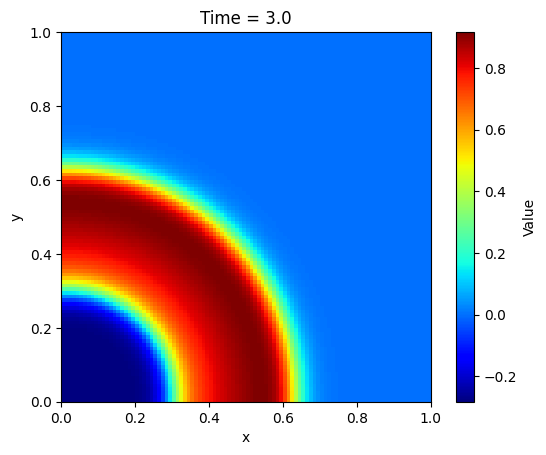

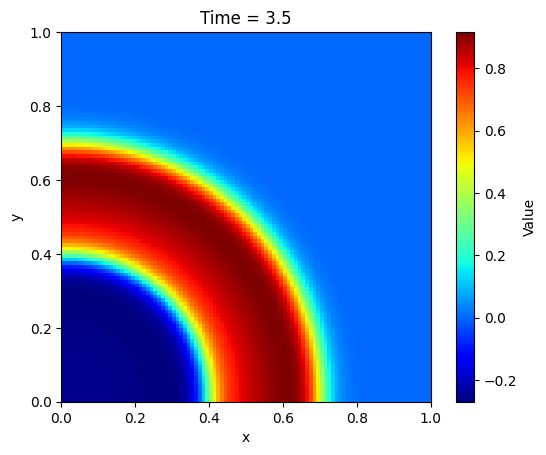

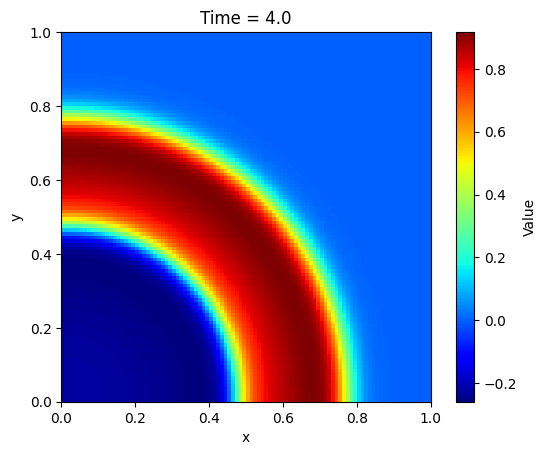

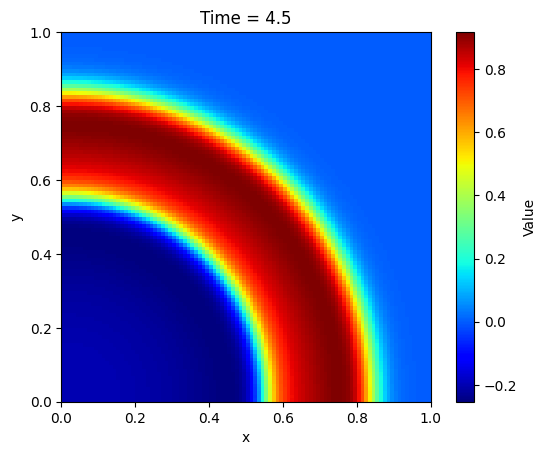

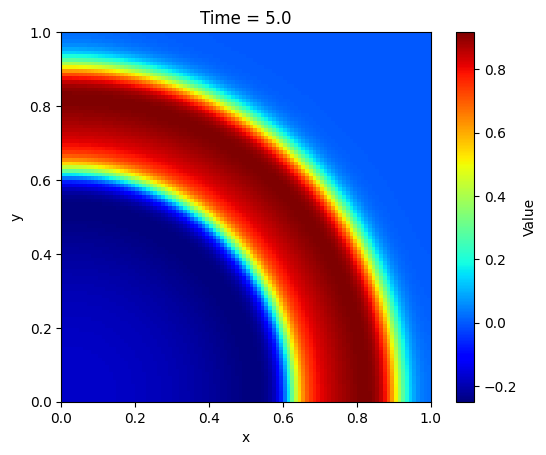

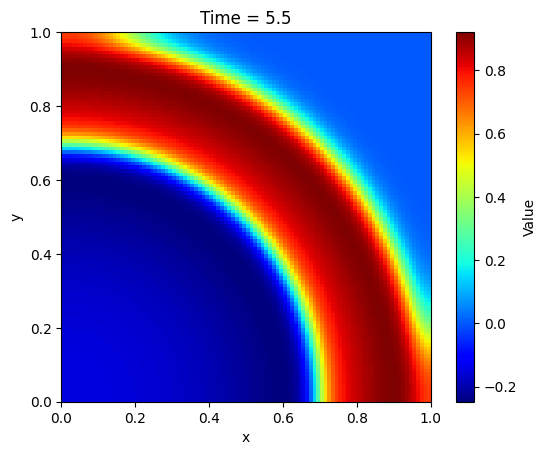

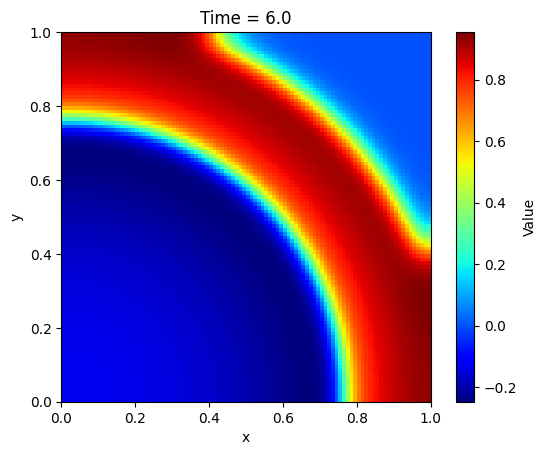

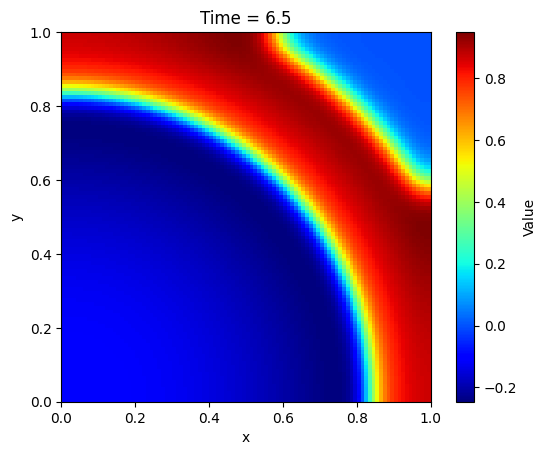

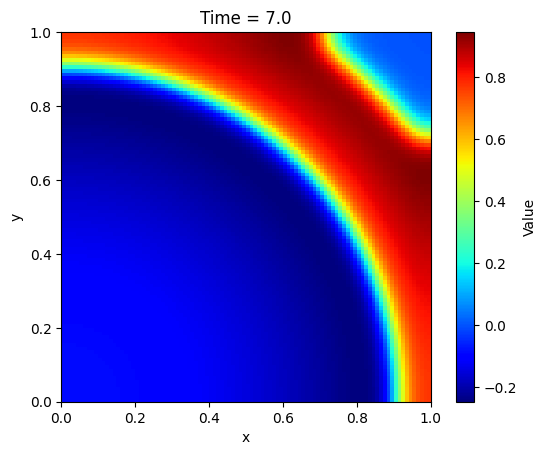

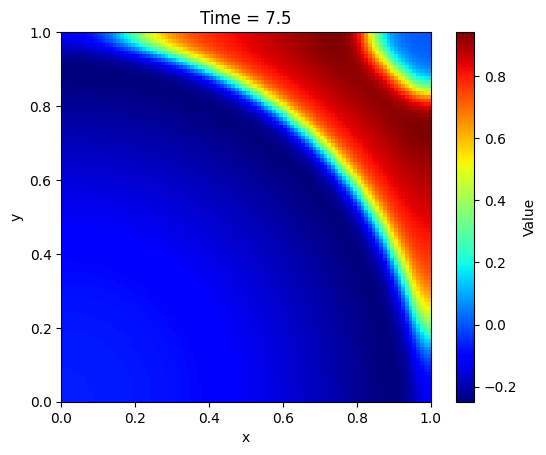

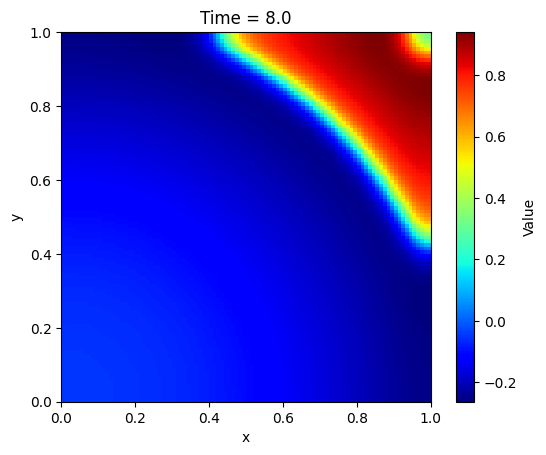

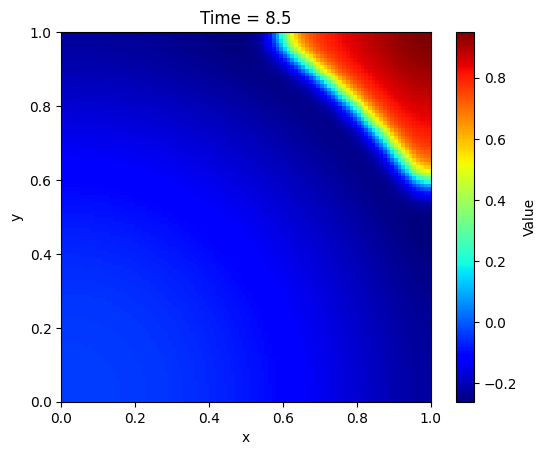

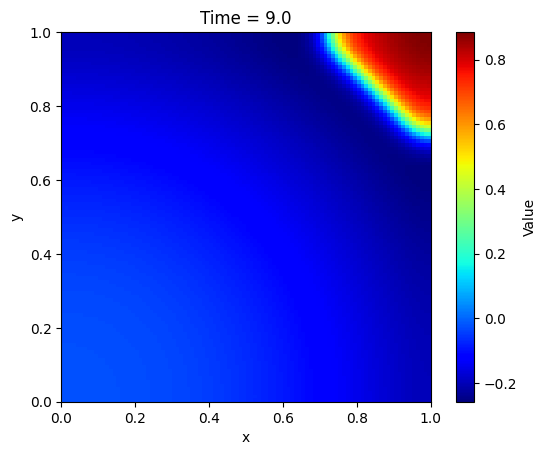

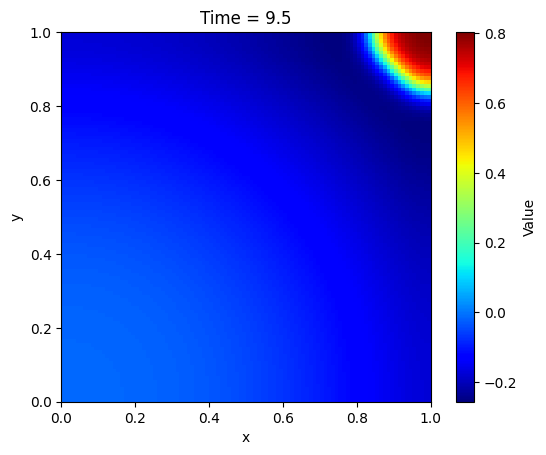

In [8]:
## Generating data
for ntime in range(nend): # 500 is the number of timesteps

    uold = u1.copy()
    vold = v1.copy()
    dv1 = eps*(beta*uold - gamma*vold -delta)
    du1 = (a-uold)*(uold-1)*uold-vold


    diff_x = np.zeros((nx, nx), dtype = float)
    diff_y = np.zeros((nx, nx), dtype = float)
    diff_x[0, :] = 2*(uold[2, :] - uold[1, :])
    diff_x[nx-1, :] = 2*(-uold[nx-1, :] + uold[nx-2, :])
    diff_x[1:-1, :] = uold[0:-2, :] - 2*uold[1:-1, :] + uold[2:, :]

    diff_y[:, 0] = 2*(uold[:, 2]-uold[:, 1])
    diff_y[:, nx-1] = 2*(-uold[:, nx-1] + uold[:, nx-2])
    diff_y[:, 1:-1] = uold[:, 0:-2] -2*uold[:, 1:-1] + uold[:, 2:]

    u1 = uold + dt*du1 + diff*dt/(dx*dx)*(diff_x+diff_y)
    v1 = vold +  dt*dv1

    if (ntime % 20 == 0):
        training_points[int(ntime/20),:, :] = u1.T
        training_points_v[int(ntime/20),:, :] = v1.T

        # plt.figure()
        # plt.imshow(u1, cmap='copper', origin='lower', extent=[x_min, x_max, y_min, y_max], vmin=-0.3, vmax=1)
        # plt.colorbar()
        # plt.title(f'Time = {ntime * dt}')
        # plt.draw()
        # plt.pause(0.001)  # Equivalent of MATLAB's drawnow
        # plt.show()
    if (ntime % 100 == 0):
        plt.figure()
        plt.imshow(u1, cmap='jet', origin='lower', extent=[0, 1, 0, 1])
        plt.colorbar(label='Value')  # Add a colorbar
        plt.title(f'Time = {ntime * 0.005}')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.show()

In [9]:
## Constants
a=0.1
gamma=1
beta=0.5
eps=0.01
delta=0

In [10]:
class FitzHughNagumo():
    def __init__(self, ic_pts, bc_pts, data_pts, res_pts):


        ## TODO : Add boundary condition loss for v?

        self.x_data = torch.tensor(data_pts[0], requires_grad=True, dtype=torch.float32)
        self.y_data = torch.tensor(data_pts[1], requires_grad=True, dtype=torch.float32)
        self.t_data = torch.tensor(data_pts[2], requires_grad=True, dtype=torch.float32)

        self.u_gt = torch.tensor(data_pts[3], requires_grad=True, dtype=torch.float32)
        self.v_gt = torch.tensor(data_pts[4], requires_grad=True, dtype=torch.float32)

        self.x_left = torch.tensor(bc_pts['left'][0], requires_grad=True, dtype=torch.float32)
        self.y_left = torch.tensor(bc_pts['left'][1], requires_grad=True, dtype=torch.float32)
        self.t_left = torch.tensor(bc_pts['left'][2], requires_grad=True, dtype=torch.float32)

        self.x_right = torch.tensor(bc_pts['right'][0], requires_grad=True, dtype=torch.float32)
        self.y_right = torch.tensor(bc_pts['right'][1], requires_grad=True, dtype=torch.float32)
        self.t_right = torch.tensor(bc_pts['right'][2], requires_grad=True, dtype=torch.float32)

        self.x_top = torch.tensor(bc_pts['top'][0], requires_grad=True, dtype=torch.float32)
        self.y_top = torch.tensor(bc_pts['top'][1], requires_grad=True, dtype=torch.float32)
        self.t_top = torch.tensor(bc_pts['top'][2], requires_grad=True, dtype=torch.float32)

        self.x_bottom = torch.tensor(bc_pts['bottom'][0], requires_grad=True, dtype=torch.float32)
        self.y_bottom = torch.tensor(bc_pts['bottom'][1], requires_grad=True, dtype=torch.float32)
        self.t_bottom = torch.tensor(bc_pts['bottom'][2], requires_grad=True, dtype=torch.float32)

        self.x_ic = torch.tensor(ic_pts[0], requires_grad=True, dtype=torch.float32)
        self.y_ic = torch.tensor(ic_pts[1], requires_grad=True, dtype=torch.float32)
        self.t_ic = torch.tensor(ic_pts[2], requires_grad=True, dtype=torch.float32)
        self.u_ic = torch.tensor(ic_pts[3], requires_grad=True, dtype=torch.float32)
        self.v_ic = torch.tensor(ic_pts[4], requires_grad=True, dtype=torch.float32)
        
        self.x_res = torch.tensor(res_pts[0], requires_grad=True, dtype=torch.float32)
        self.y_res = torch.tensor(res_pts[1], requires_grad=True, dtype=torch.float32)
        self.t_res = torch.tensor(res_pts[2], requires_grad=True, dtype=torch.float32)
        
     
        
        
        
        self.data_losses = []
        self.pde_losses = []
        self.bc_losses = []
        self.ic_losses = []
        
        self.losses = [] 




        # initialize network:
        self.network()

        self.optimizer_adam = torch.optim.Adam(self.net.parameters(), lr = 1e-3)

        self.optimizer = torch.optim.LBFGS(self.net.parameters(), lr=0.1, max_iter=20000, max_eval=50000,
                                           history_size=50, tolerance_grad=1e-04, tolerance_change=0.5 * np.finfo(float).eps,
                                           line_search_fn="strong_wolfe")

        self.mse = nn.MSELoss()

        #loss
        self.ls = 0

        #iteration number
        self.iter = 0

    def network(self):

         self.net = nn.Sequential(
            nn.Linear(3, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 2))

    def function(self, x, y, t):

        res = self.net(torch.hstack((x, y, t)))
        u, v = res[:, 0:1], res[:, 1:2]


        u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        v_t = torch.autograd.grad(v, t, grad_outputs=torch.ones_like(v), create_graph=True)[0]

        u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
        
        u_y = torch.autograd.grad(u, y, torch.ones_like(u), create_graph=True)[0]
        u_yy = torch.autograd.grad(u_y, y, torch.ones_like(u_y), create_graph=True)[0]

        f = u_t - (u_xx + u_yy + (a - u)*(u - 1)*u - v)

        g = v_t - (eps*(beta*u - gamma*v - delta))

        return u, v, f, g

    def closure(self):

        # reset gradients to zero:
        self.optimizer_adam.zero_grad()
        self.optimizer.zero_grad()

        # --- PDE & DATA LOSS ---
        u_data, v_data, _, _ = self.function(self.x_data, self.y_data, self.t_data)
        
        _, _, f_res, g_res = self.function(self.x_res, self.y_res, self.t_res)

        loss_pde = self.mse(f_res, torch.zeros_like(f_res)) + self.mse(g_res, torch.zeros_like(g_res))
        loss_data = self.mse(u_data, self.u_gt) + self.mse(v_data, self.v_gt)

        # --- INITIAL CONDITION LOSS ---
        res_ic = self.net(torch.hstack((self.x_ic, self.y_ic, self.t_ic)))
        loss_ic = self.mse(res_ic[:,0:1], self.u_ic) + self.mse(res_ic[:,1:2], self.v_ic)

       # --- NEUMANN BOUNDARY LOSS (Zero Flux for u AND v) ---

        # LEFT (∂/∂x = 0)
        uv_left = self.net(torch.hstack((self.x_left, self.y_left, self.t_left)))
        u_left = uv_left[:, 0:1]
        v_left = uv_left[:, 1:2]

        du_dx_left = torch.autograd.grad(u_left, self.x_left, torch.ones_like(u_left), create_graph=True)[0]
        dv_dx_left = torch.autograd.grad(v_left, self.x_left, torch.ones_like(v_left), create_graph=True)[0]

        loss_bc_left = self.mse(du_dx_left, torch.zeros_like(du_dx_left)) + \
                       self.mse(dv_dx_left, torch.zeros_like(dv_dx_left))


        # RIGHT (∂/∂x = 0)
        uv_right = self.net(torch.hstack((self.x_right, self.y_right, self.t_right)))
        u_right = uv_right[:, 0:1]
        v_right = uv_right[:, 1:2]

        du_dx_right = torch.autograd.grad(u_right, self.x_right, torch.ones_like(u_right), create_graph=True)[0]
        dv_dx_right = torch.autograd.grad(v_right, self.x_right, torch.ones_like(v_right), create_graph=True)[0]

        loss_bc_right = self.mse(du_dx_right, torch.zeros_like(du_dx_right)) + \
                        self.mse(dv_dx_right, torch.zeros_like(dv_dx_right))


        # TOP (∂/∂y = 0)
        uv_top = self.net(torch.hstack((self.x_top, self.y_top, self.t_top)))
        u_top = uv_top[:, 0:1]
        v_top = uv_top[:, 1:2]

        du_dy_top = torch.autograd.grad(u_top, self.y_top, torch.ones_like(u_top), create_graph=True)[0]
        dv_dy_top = torch.autograd.grad(v_top, self.y_top, torch.ones_like(v_top), create_graph=True)[0]

        loss_bc_top = self.mse(du_dy_top, torch.zeros_like(du_dy_top)) + \
                      self.mse(dv_dy_top, torch.zeros_like(dv_dy_top))


        # BOTTOM (∂/∂y = 0)
        uv_bottom = self.net(torch.hstack((self.x_bottom, self.y_bottom, self.t_bottom)))
        u_bottom = uv_bottom[:, 0:1]
        v_bottom = uv_bottom[:, 1:2]

        du_dy_bottom = torch.autograd.grad(u_bottom, self.y_bottom, torch.ones_like(u_bottom), create_graph=True)[0]
        dv_dy_bottom = torch.autograd.grad(v_bottom, self.y_bottom, torch.ones_like(v_bottom), create_graph=True)[0]

        loss_bc_bottom = self.mse(du_dy_bottom, torch.zeros_like(du_dy_bottom)) + \
                         self.mse(dv_dy_bottom, torch.zeros_like(dv_dy_bottom))


        loss_bc = loss_bc_left + loss_bc_right + loss_bc_top + loss_bc_bottom




        print(loss_bc_left, loss_bc_right, loss_bc_top, loss_bc_bottom)
       

        print(loss_pde, loss_data, loss_ic, loss_bc)
        self.ls =  loss_pde + 1000*loss_data + loss_ic + 10*loss_bc
        
       
            
        
        self.pde_losses.append(loss_pde.item())
        self.data_losses.append(loss_data.item())
        self.ic_losses.append(loss_ic.item())
        self.bc_losses.append(loss_bc.item())
        self.losses.append(self.ls.item())

        # derivative with respect to net's weights:
        

        self.ls.backward()

        self.iter += 1
        print(f'Iteration: {self.iter}, Loss: {self.ls.item():.6f}')

        return self.ls
    
    

    def train(self, adam_epochs=20000):
        self.net.train()

        for epoch in range(adam_epochs):
            loss = self.closure()
            self.optimizer_adam.step()
            
                
        def lbfgs_closure():
            return self.closure()

        self.optimizer.step(lbfgs_closure)


### Time Window Marching Setup

We will divide the total time domain `[t_min, t_max]` into `num_time_windows` smaller segments. For each segment, a new PINN will be trained. The initial conditions for the current time window will be provided by the prediction of the previous PINN at the end of its time domain. For the very first window, the original initial conditions will be used.

In [11]:
# Define the number of time windows
num_time_windows = 10

# Calculate the duration of each time window
dt_window = (t_max - t_min) / num_time_windows
print(f"Total time domain: [{t_min}, {t_max}]")
print(f"Number of time windows: {num_time_windows}")
print(f"Duration of each time window: {dt_window}")

Total time domain: [0, 10]
Number of time windows: 10
Duration of each time window: 1.0


In [12]:
print(dt_window)

1.0


In [13]:
def sample(mask, n_samples):
    # Get indices where mask is True
    indices = np.where(mask)[0]

    # Randomly pick n_samples indices without replacement
    sampled_indices = np.random.choice(indices, size=min(n_samples, len(indices)), replace=False)

    # Return the sliced data
    return x[sampled_indices], y[sampled_indices], t[sampled_indices], u[sampled_indices], v[sampled_indices]

# Suggested sample sizes for L-BFGS efficiency
N_ic = 1000
N_bc = 1000
N_f  = 2000
N_res = 5000



### Modified Data Sampling Function for Time Windows

This function will be used to sample data points (initial conditions, boundary conditions, and collocation points) specific to each time window. For the initial conditions of a given window, it will either use the original initial data (for the first window) or predictions from the previous trained PINN.

In [14]:

## define x,y,t,u and v
x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
t = np.linspace(0, 10, 100)



In [15]:
X, Y, T = np.meshgrid(y,x,t,indexing='xy')
x = X.ravel().reshape(1000000, 1)
y = Y.ravel().reshape(1000000, 1)
t = T.ravel().reshape(1000000, 1)

In [16]:
u = np.zeros((1000000, 1))
v = np.zeros((1000000, 1))
count = 0
for i in range(100):
    for j in range(100):
        for k in range(100):
            # print(k,i,j)
            u[count] = training_points[k, j, i]
            v[count] = training_points_v[k, j, i]
            count += 1



In [17]:
print(x.shape, y.shape, t.shape)

(1000000, 1) (1000000, 1) (1000000, 1)


In [18]:
def sample_data_for_window(t_start_window, t_end_window,
                          u_initial_prev_window=None,
                          v_initial_prev_window=None):

    mask_window = (t >= t_start_window) & (t <= t_end_window)

    mask_ic_current_window = (t == t_start_window) & mask_window
    mask_f_current_window = (t > t_start_window) & (t <= t_end_window)

    mask_bc_left_current_window   = (x == x_min) & mask_window
    mask_bc_right_current_window  = (x == x_max) & mask_window
    mask_bc_top_current_window    = (y == y_max) & mask_window
    mask_bc_bottom_current_window = (y == y_min) & mask_window


    # -------------------------
    # INITIAL CONDITIONS
    # -------------------------
    if u_initial_prev_window is not None:

        x_ic = x[mask_ic_current_window].reshape(-1,1)
        y_ic = y[mask_ic_current_window].reshape(-1,1)
        t_ic = t[mask_ic_current_window].reshape(-1,1)

        u_ic = u_initial_prev_window.reshape(-1,1)
        v_ic = v_initial_prev_window.reshape(-1,1)

        idx = np.random.choice(len(x_ic), size=min(N_ic, len(x_ic)), replace=False)

        x_ic = x_ic[idx]
        y_ic = y_ic[idx]
        t_ic = t_ic[idx]
        u_ic = u_ic[idx]
        v_ic = v_ic[idx]

    else:

        x_ic, y_ic, t_ic, u_ic, v_ic = sample(mask_ic_current_window, N_ic)

        x_ic = x_ic.reshape(-1,1)
        y_ic = y_ic.reshape(-1,1)
        t_ic = t_ic.reshape(-1,1)
        u_ic = u_ic.reshape(-1,1)
        v_ic = v_ic.reshape(-1,1)

    ic_pts = [x_ic, y_ic, t_ic, u_ic, v_ic]


    # -------------------------
    # Anchor points
    # -------------------------
    x_f, y_f, t_f, u_f, v_f = sample(mask_f_current_window, N_f)

    x_f = x_f.reshape(-1,1)
    y_f = y_f.reshape(-1,1)
    t_f = t_f.reshape(-1,1)
    u_f = u_f.reshape(-1,1)
    v_f = v_f.reshape(-1,1)

    f_pts = [x_f, y_f, t_f, u_f, v_f]


    # -------------------------
    # BOUNDARY CONDITIONS
    # -------------------------
    def sample_bc(mask):
        x_bc, y_bc, t_bc, _, _ = sample(mask, N_bc)

        x_bc = x_bc.reshape(-1,1)
        y_bc = y_bc.reshape(-1,1)
        t_bc = t_bc.reshape(-1,1)

        return [x_bc, y_bc, t_bc]

    bc_left   = sample_bc(mask_bc_left_current_window)
    bc_right  = sample_bc(mask_bc_right_current_window)
    bc_top    = sample_bc(mask_bc_top_current_window)
    bc_bottom = sample_bc(mask_bc_bottom_current_window)

    bc_pts = {
        "left": bc_left,
        "right": bc_right,
        "top": bc_top,
        "bottom": bc_bottom
    }


    # -------------------------
    # RESIDUAL SAMPLING (NEW)
    # -------------------------
    x_res = np.random.uniform(0.0, 1.0, (N_res, 1))
    y_res = np.random.uniform(0.0, 1.0, (N_res, 1))
    t_res = np.random.uniform(t_start_window + 1, t_end_window + 1, (N_res, 1))

    res_pts = [x_res, y_res, t_res]


    return ic_pts, bc_pts, f_pts, res_pts

In [19]:
times = []
for i in range(100):
    if i % 10 == 0:
        times.append(t[i][0])
    

In [20]:
mask_ic = (t == t_min).flatten()
mask_bc_left = ((x==x_min))
mask_bc_right = ((x==x_max))
mask_bc_top = ((y==y_max))
mask_bc_bottom = ((y==y_min))
mask_f = np.ones_like(mask_ic, dtype=bool)

In [21]:
print(times)

[0.0, 1.0101010101010102, 2.0202020202020203, 3.0303030303030303, 4.040404040404041, 5.05050505050505, 6.0606060606060606, 7.070707070707071, 8.080808080808081, 9.09090909090909]


In [22]:
x_ic, y_ic, t_ic, u_ic, v_ic = sample(mask_ic, N_ic)
x_bc_left, y_bc_left, t_bc_left, u_bc_left, v_bc_left = sample(mask_bc_left, N_bc)
x_bc_right, y_bc_right, t_bc_right, u_bc_right, v_bc_right = sample(mask_bc_right, N_bc)
x_bc_top, y_bc_top, t_bc_top, u_bc_top, v_bc_top = sample(mask_bc_top, N_bc)
x_bc_bottom, y_bc_bottom, t_bc_bottom, u_bc_bottom, v_bc_bottom = sample(mask_bc_bottom, N_bc)
x_f, y_f, t_f, u_f, v_f = sample(mask_f, N_f)

x_res = np.random.uniform(0, 1, (N_res, 1))
y_res = np.random.uniform(0, 1, (N_res, 1))
t_res = np.random.uniform(times[0], times[1], (N_res, 1))

In [23]:
ic_pts = [x_ic, y_ic, t_ic, u_ic, v_ic]

bc_left = [x_bc_left, y_bc_left, t_bc_left]
bc_right = [x_bc_right, y_bc_right, t_bc_right]
bc_top = [x_bc_top, y_bc_top, t_bc_top]
bc_bottom = [x_bc_bottom, y_bc_bottom, t_bc_bottom]

bcs = [bc_left, bc_right, bc_top, bc_bottom]
bc_pts = {}
for i, item in enumerate(['left', 'right', 'top', 'bottom']):
  bc_pts[item] = bcs[i]

f_pts = [x_f, y_f, t_f, u_f, v_f]
res_pts = [x_res, y_res, t_res]


### Main Time Marching Training Loop

This loop will iterate through each time window, train a dedicated PINN for that window, and use its predictions to set up the initial conditions for the subsequent window. We will store each trained model for later use.

In [36]:
all_trained_models = []
trained_model_losses = []
u_prev_window_ic = None
v_prev_window_ic = None

adam_epochs = 2000 # Number of Adam optimization steps per window
lbfgs_epochs = 5000 # Max L-BFGS iterations per window

for i in range(len(times)-1):
    t_start_current_window = times[i]
    t_end_current_window = times[i+1]

    print(f"\n--- Training for Time Window {i+1}/{num_time_windows}: [{t_start_current_window:.3f}, {t_end_current_window:.3f}] ---")

    # Sample data for the current window
    ic_pts_window, bc_pts_window, f_pts_window, res_pts_window = sample_data_for_window(
        t_start_current_window, t_end_current_window,
        u_prev_window_ic, v_prev_window_ic
    )

    # Instantiate a new PINN for the current time window
    pinn_window = FitzHughNagumo(ic_pts_window, bc_pts_window, f_pts_window, res_pts_window)

    # Training loop for the current PINN
    pinn_window.net.train()
    for epoch in range(adam_epochs):
      pinn_window.optimizer_adam.step(pinn_window.closure)

    pinn_window.optimizer.step(pinn_window.closure)

    # Save the trained model state
    model_filename = f'model_window_{i+1}.pt'
    torch.save(pinn_window.net.state_dict(), model_filename)
    all_trained_models.append(pinn_window.net)
    trained_model_losses.append(pinn_window.losses)
    print(f"Model for window {i+1} saved to {model_filename}")

    # Prepare initial conditions for the next window
    # Predict u and v at the end of the current window (t_end_current_window)
    # These points should be the same x, y grid points as in the original data
    # For simplification, we will use the global x,y and the t_end_current_window

    # Create a tensor for the end time of the current window for prediction
    # Need to match the shape of x, y used for prediction
    # For now, let's assume we want predictions over the whole spatial domain at this specific time
    # Reshape x, y to be consistent with how function expects input

    # We need to collect all unique (x,y) pairs from the original data that were within this window
    # and predict u, v at t_end_current_window for all these (x,y)

    # For the purpose of getting ICs for the next step, let's consider a spatial grid at t_end_current_window
    # Reconstruct a grid for prediction at t_end_current_window

    # If it's the last window, no need to prepare IC for the next.
    if i < num_time_windows - 1:
        # Generate a grid of (x,y) points for prediction at t_end_current_window
        nx_grid = np.linspace(x_min, x_max, 100)
        ny_grid = np.linspace(y_min, y_max, 100)
        X_grid, Y_grid = np.meshgrid(nx_grid, ny_grid, indexing='xy')

        x_flat_pred = torch.tensor(X_grid.ravel().reshape(-1, 1), dtype=torch.float32, requires_grad=True)
        y_flat_pred = torch.tensor(Y_grid.ravel().reshape(-1, 1), dtype=torch.float32, requires_grad=True)
        t_flat_pred = torch.full_like(x_flat_pred, t_end_current_window, requires_grad=True)

        pinn_window.net.eval()
        with torch.no_grad():
            res_pred = pinn_window.net(torch.hstack((x_flat_pred, y_flat_pred, t_flat_pred)))
            u_pred_next_window_ic = res_pred[:, 0:1].cpu().numpy()
            v_pred_next_window_ic = res_pred[:, 1:2].cpu().numpy()

        u_prev_window_ic = u_pred_next_window_ic
        v_prev_window_ic = v_pred_next_window_ic


In [37]:

fig, ax = plt.subplots()
indices = np.where(np.isclose(t, 2.020202))[0]
plt.contourf(u[indices].reshape(100,100), levels=30, cmap='jet')
plt.colorbar()

In [ ]:
pinn = FitzHughNagumo(ic_pts, bc_pts, f_pts)

pinn.train()

torch.save(pinn.net.state_dict(), 'model.pt')

In [53]:
## Testing Data
idx = np.where(np.isclose(t, 7.070707))[0]
print(idx)
t_test = t[idx]
x_test = x[idx]
y_test = y[idx]

[    70    170    270 ... 999770 999870 999970]


In [39]:

x_test = torch.tensor(x_test, dtype=torch.float32, requires_grad=True)
y_test = torch.tensor(y_test, dtype=torch.float32, requires_grad=True)
t_test = torch.tensor(t_test, dtype=torch.float32, requires_grad=True)


In [40]:
import imageio
import os

In [41]:
def generate_u_gif(
    model_paths,
    times,
    x_flat,
    y_flat,
    Nt=50,
    filename="u_prediction.gif",
    levels=30,
    cmap="jet"
):

    """
    Generate a GIF using multiple trained PINN window models.

    Parameters
    ----------
    pinn : FitzHughNagumo
        Model architecture (weights will be loaded repeatedly)
    model_paths : list[str]
        Paths to saved model weights for each window
    times : list[float]
        Time boundaries for windows (length = num_windows + 1)
    x_flat, y_flat : torch.Tensor
        Flattened spatial grid (N,1)
    Nt : int
        Frames per window
    """
    pinn = FitzHughNagumo(ic_pts, bc_pts, f_pts, res_pts)
    pinn.net.eval()

    Nx, Ny = 100, 100
    frames = []

    num_windows = len(model_paths)

    for i in range(num_windows):

        print(f"Loading window model {i}")

        # Load weights for this window
        pinn.net.load_state_dict(torch.load(model_paths[i]))
        pinn.net.eval()

        t_start = times[i]
        t_end = times[i+1]

        # Time samples inside this window
        for t_val in np.linspace(t_start, t_end, Nt):

            t_test = np.full((Nx * Ny, 1), t_val)
            t_flat = torch.tensor(t_test, dtype=torch.float32, requires_grad=True)

            
            u_pred, _, _, _ = pinn.function(x_flat, y_flat, t_flat)

            u_plot = u_pred.detach().cpu().numpy().reshape(Nx, Ny)

            # Plot frame
            fig, ax = plt.subplots(figsize=(5, 4))

            contour = ax.contourf(
                u_plot,
                levels=levels,
                cmap=cmap
            )

            ax.set_title(f"u(x,y,t), t = {t_val:.3f}")
            ax.set_xlabel("x")
            ax.set_ylabel("y")

            fig.colorbar(contour)

            fig.canvas.draw()

            buf = np.asarray(fig.canvas.buffer_rgba())
            image = buf[..., :3]

            frames.append(image)

            plt.close(fig)

    imageio.mimsave(filename, frames, fps=8)

    print(f"GIF saved to {filename}")

In [42]:
model_paths = [
    "model_window_1.pt",
    "model_window_2.pt",
    "model_window_3.pt",
    "model_window_4.pt",
    "model_window_5.pt",
    "model_window_6.pt",
    "model_window_7.pt",
    "model_window_8.pt",
    "model_window_9.pt"
]

generate_u_gif(
    model_paths,
    times,
    x_test,
    y_test,
    Nt=8,
    filename="fhn_prediction.gif"
)

In [52]:
print(1)

1


Timestep t = 8.00
Relative L2 Error: 0.243284
RMSE: 0.082009
MAE: 0.049099
Accuracy (1 - rel L2): 0.756716


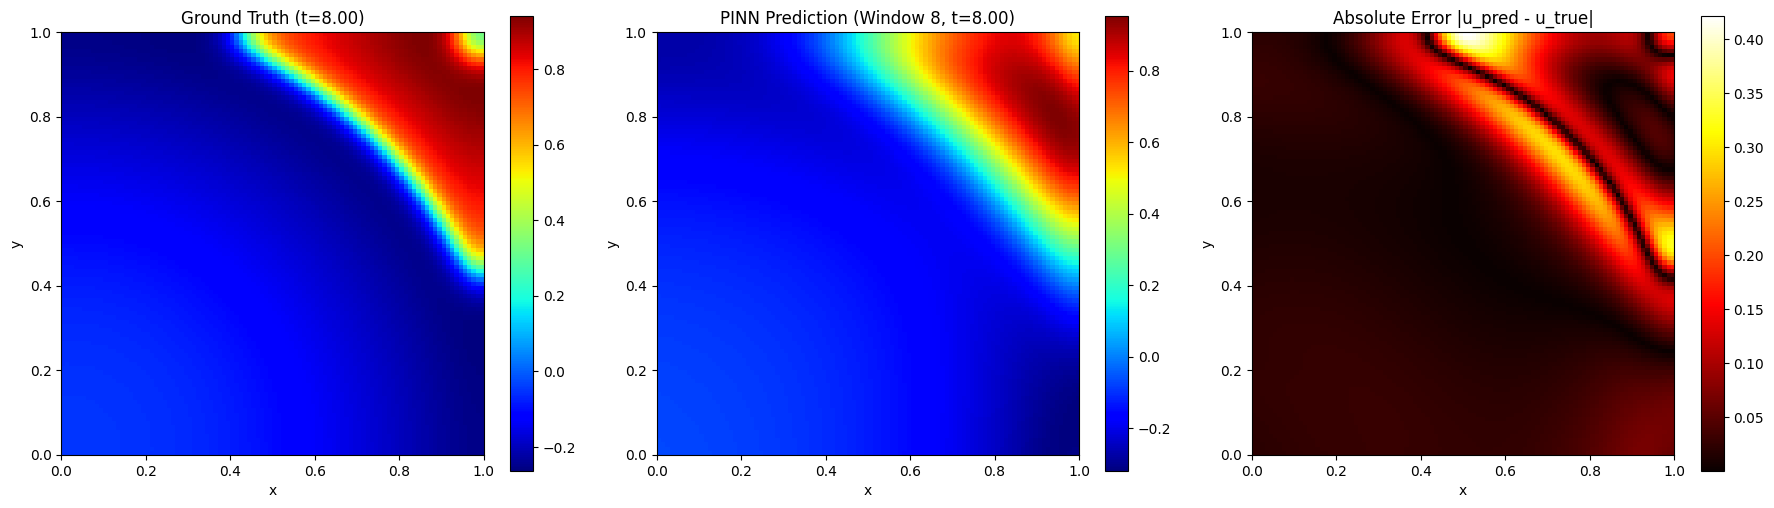

In [33]:
# timestep to evaluate
t_index = 80
time_val = t_index / 10   # physical time

# ground truth
u_true = training_points[t_index,:,:]

# -------------------------
# time window parameters
# -------------------------
window_size = 1.0  # example: each model covers 2 units of time
window_id = int(time_val // window_size)

# load the correct window model
model_path = f"model_window_{8}.pt"

pinn = FitzHughNagumo(ic_pts, bc_pts, f_pts, res_pts)
pinn.net.load_state_dict(torch.load(model_path))
pinn.net.eval()

# local time inside window
local_time = time_val - window_id * window_size

# -------------------------
# create grid
# -------------------------
x = np.linspace(0,1,100)
y = np.linspace(0,1,100)
X, Y = np.meshgrid(x,y)

x_test = torch.tensor(X.flatten()[:,None], dtype=torch.float32, requires_grad=True)
y_test = torch.tensor(Y.flatten()[:,None], dtype=torch.float32, requires_grad=True)

t_test = torch.tensor(
    np.full_like(X.flatten()[:,None], time_val),
    dtype=torch.float32,
    requires_grad=True
)

# -------------------------
# PINN prediction
# -------------------------
u_out, v_out, f_out, g_out = pinn.function(x_test, y_test, t_test)

u_pred = u_out.detach().cpu().numpy().reshape(100,100)

# -------------------------
# error
# -------------------------
error = np.abs(u_true - u_pred)
rel_l2_error = np.linalg.norm(u_true - u_pred) / np.linalg.norm(u_true)

# RMSE
rmse = np.sqrt(np.mean((u_true - u_pred)**2))

# MAE
mae = np.mean(np.abs(u_true - u_pred))

# "Accuracy" (optional interpretation)
accuracy = 1 - rel_l2_error

print(f"Timestep t = {time_val:.2f}")
print(f"Relative L2 Error: {rel_l2_error:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MAE: {mae:.6f}")
print(f"Accuracy (1 - rel L2): {accuracy:.6f}")

# -------------------------
# plotting
# -------------------------
fig, axs = plt.subplots(1,3, figsize=(18,5))

gt = axs[0].imshow(u_true, cmap='jet', origin='lower', extent=[0,1,0,1])
axs[0].set_title(f"Ground Truth (t={time_val:.2f})")
fig.colorbar(gt, ax=axs[0])

pred = axs[1].imshow(u_pred, cmap='jet', origin='lower', extent=[0,1,0,1])
axs[1].set_title(f"PINN Prediction (Window {window_id}, t={time_val:.2f})")
fig.colorbar(pred, ax=axs[1])

err = axs[2].imshow(error, cmap='hot', origin='lower', extent=[0,1,0,1])
axs[2].set_title("Absolute Error |u_pred - u_true|")
fig.colorbar(err, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

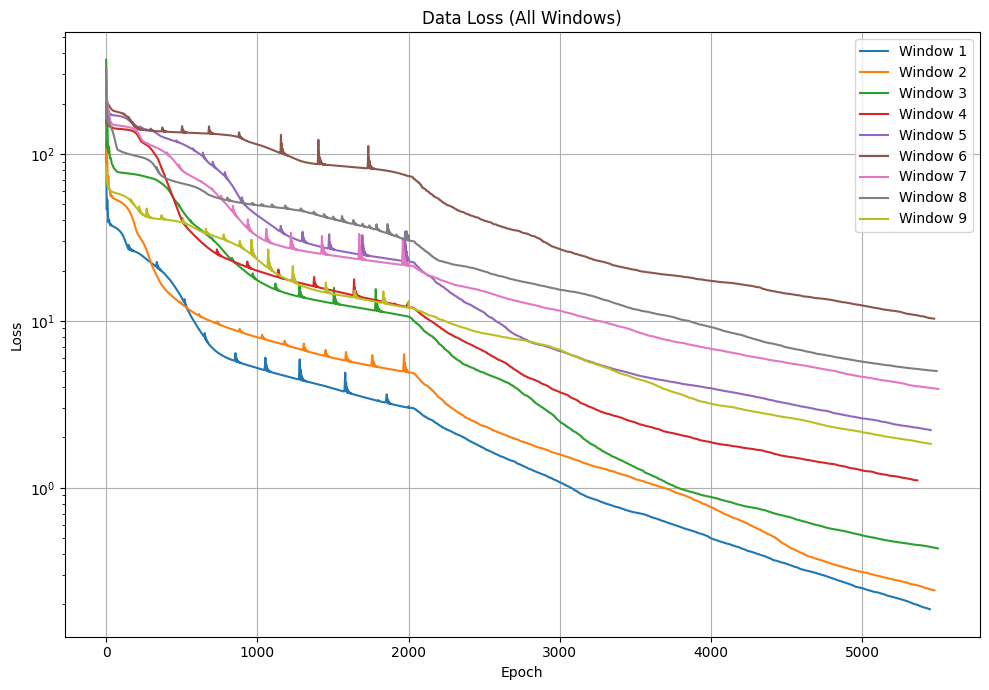

In [73]:
fig, ax = plt.subplots(figsize=(10,7))

for i in range(len(trained_model_losses)):
    ax.plot(trained_model_losses[i], label=f"Window {i+1}")

ax.set_title("Data Loss (All Windows)")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

IndexError: index 4 is out of bounds for axis 0 with size 4

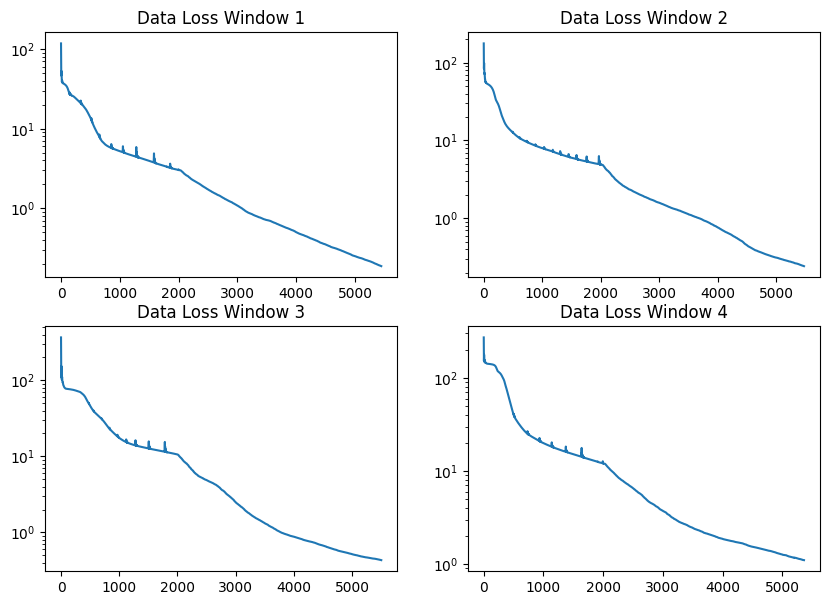

In [74]:
fig, axs = plt.subplots(2, 2, figsize=(10,7))
axs = axs.flatten()

for i in range(len(trained_model_losses)):
    axs[i].plot(trained_model_losses[i])
    axs[i].set_title(f"Data Loss Window {i + 1}")
    axs[i].set_yscale("log")

# formatting ALL axes after plotting
for ax in axs:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)

plt.tight_layout()
plt.show()